In [ ]:
import pandas as pd

# 1. Carregar o conjunto de dados do compressor de ar a partir de um ficheiro CSV
df = pd.read_csv("MetroPT3(AirCompressor).csv")

# 2. Remover a coluna "Unnamed: 0" que geralmente surge do índice guardado no CSV
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# 3. Converter a coluna "timestamp" de texto (string) para o formato de data e hora (datetime) do Pandas
df["timestamp"] = pd.to_datetime(df["timestamp"])

# 4. Ordenar os dados por ordem cronológica (do mais antigo para o mais recente) e reiniciar os índices
df = df.sort_values("timestamp").reset_index(drop=True)

# 5. Imprimir estatísticas básicas e inspeção inicial dos dados em português bem estruturado
print("==================================================")
print("       RELATÓRIO DE INSPEÇÃO INICIAL DOS DADOS    ")
print("==================================================\n")

print(f"-> Dimensão do Dataset (Linhas x Colunas):")
print(f"   {df.shape[0]} linhas e {df.shape[1]} colunas\n")

print(f"-> Período Coberto:")
print(f"   Início: {df['timestamp'].min()} | Fim: {df['timestamp'].max()}\n")

print(f"-> Verificação do Tipo de Dados do Timestamp:")
print(f"   {df['timestamp'].dtype}\n")

print("-> Tipos de Dados de Todas as Colunas:")
print(df.dtypes.to_string())
print("\n" + "-"*50 + "\n")

total_nulos = df.isna().sum().sum()
print(f"-> Total de Valores em Falta (Nulos) no Dataset: {total_nulos}\n")

print("-> Estatísticas Descritivas (Média, Mínimo, Máximo, Desvio Padrão, etc.):")
print(df.describe().T.to_string())
print("\n==================================================")

       RELATÓRIO DE INSPEÇÃO INICIAL DOS DADOS    

-> Dimensão do Dataset (Linhas x Colunas):
   1516948 linhas e 16 colunas

-> Período Coberto:
   Início: 2020-02-01 00:00:00 | Fim: 2020-09-01 03:59:50

-> Verificação do Tipo de Dados do Timestamp:
   datetime64[us]

-> Tipos de Dados de Todas as Colunas:
timestamp          datetime64[us]
TP2                       float64
TP3                       float64
H1                        float64
DV_pressure               float64
Reservoirs                float64
Oil_temperature           float64
Motor_current             float64
COMP                      float64
DV_eletric                float64
Towers                    float64
MPG                       float64
LPS                       float64
Pressure_switch           float64
Oil_level                 float64
Caudal_impulses           float64

--------------------------------------------------

-> Total de Valores em Falta (Nulos) no Dataset: 0

-> Estatísticas Descritivas (Média, Mínim

         DISTRIBUIÇÃO DA VARIÁVEL-ALVO            

-> Normal (0): 1 486 994 registos (98.03%)
-> Falha  (1):    29 954 registos (1.97%)

[AVISO] Dataset muito desequilibrado: um modelo que diga
sempre 'normal' já teria 98.0% de accuracy.



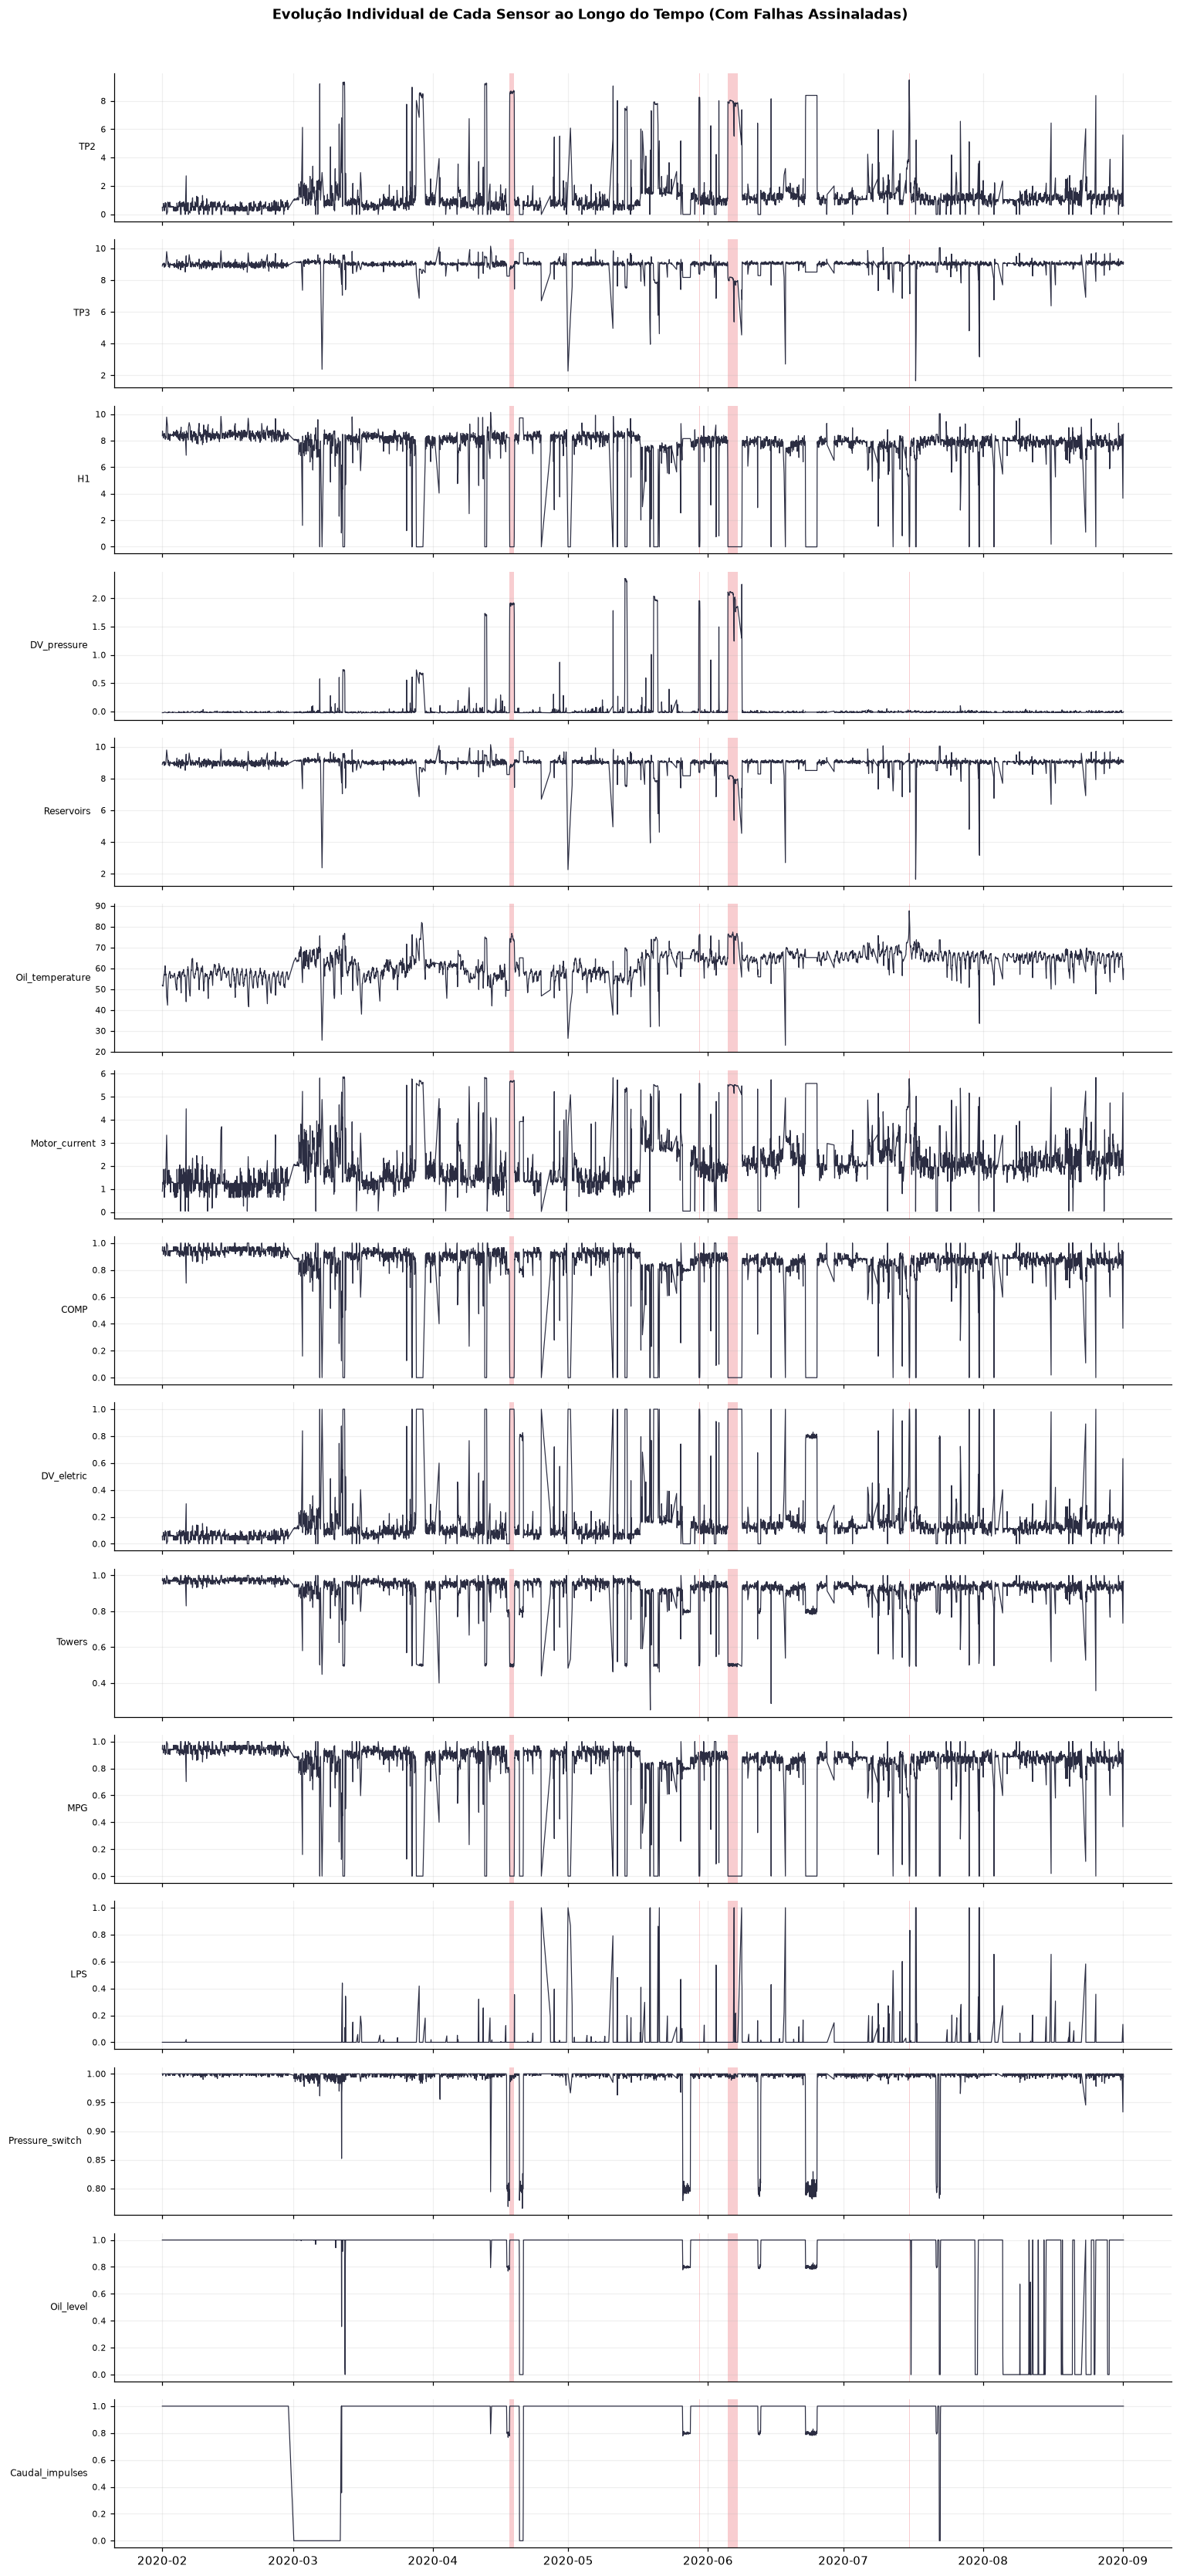

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Nota: Certifique-se de que o DataFrame 'df' já foi carregado e processado 
# com a coluna 'timestamp' em formato datetime, conforme os passos anteriores.

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COR_NORMAL, COR_FALHA, COR_TREINO, COR_TESTE = "#2a9d8f", "#e63946", "#457b9d", "#f4a261"

# 6. Períodos de avaria (relatório oficial da documentação do MetroPT-3, UCI dataset 791)
falhas = [
    ("2020-04-18 00:00", "2020-04-18 23:59"),
    ("2020-05-29 23:30", "2020-05-30 06:00"),
    ("2020-06-05 10:00", "2020-06-07 14:30"),
    ("2020-07-15 14:30", "2020-07-15 19:00"),
]
episodios = [(pd.Timestamp(i), pd.Timestamp(f)) for i, f in falhas]
NOMES_EP = ["Falha 1 (18/abr)", "Falha 2 (29-30/mai)", "Falha 3 (5-7/jun)", "Falha 4 (15/jul)"]

# 7. Coluna alvo: 0 = funcionamento normal, 1 = falha
df["falha"] = 0
for inicio, fim in falhas:
    df.loc[df["timestamp"].between(inicio, fim), "falha"] = 1

def sombrear_falhas(ax, ts_ini=None, ts_fim=None):
    """Pinta a vermelho, num gráfico temporal, os períodos de falha reais."""
    primeiro = True
    for ini, fim in episodios:
        if ts_ini is not None and (fim < ts_ini or ini > ts_fim):
            continue
        ax.axvspan(ini, fim, color=COR_FALHA, alpha=.25, lw=0, label="Falha real" if primeiro else None)
        primeiro = False

# 8. Distribuição das classes com estrutura formal em português
cont = df["falha"].value_counts().sort_index()

print("==================================================")
print("         DISTRIBUIÇÃO DA VARIÁVEL-ALVO            ")
print("==================================================\n")
print(f"-> Normal (0): {cont.get(0, 0):>9,} registos ({cont.get(0, 0)/len(df):.2%})".replace(",", " "))
print(f"-> Falha  (1): {cont.get(1, 0):>9,} registos ({cont.get(1, 0)/len(df):.2%})".replace(",", " "))
print("\n[AVISO] Dataset muito desequilibrado: um modelo que diga")
print(f"sempre 'normal' já teria {cont.get(0, 0)/len(df):.1%} de accuracy.\n")
print("==================================================")

# ==========================================
# GRÁFICO MULTI-PAINEL (FÁCIL DE LER)
# ==========================================

# 1. Agregação temporal por hora (com '1h' em minúscula para compatibilidade com o Pandas moderno)[cite: 10]
amostra_limpa = df.set_index("timestamp").resample("1h").mean().dropna().reset_index()

# 2. Selecionar os sensores (excluindo timestamp e a coluna falha)[cite: 10]
colunas_sensores = [c for c in amostra_limpa.columns if c not in ["timestamp", "falha"]]
n_sensores = len(colunas_sensores)

# 3. Criar subplots empilhados (um painel vertical para cada sensor)[cite: 10]
fig, axs = plt.subplots(n_sensores, 1, figsize=(14, 2 * n_sensores), sharex=True)

if n_sensores == 1:
    axs = [axs] # Garantir que é tratada como lista se houver apenas 1

for i, col in enumerate(colunas_sensores):
    ax = axs[i]
    
    # Desenhar a linha do sensor (sem alterar os dados originais, apenas usando a versão reamostrada para visualização)[cite: 10]
    ax.plot(amostra_limpa["timestamp"], amostra_limpa[col], lw=0.8, color="#2b2d42", label=col)
    
    # Sombrear as falhas em cada um dos painéis[cite: 10]
    sombrear_falhas(ax)
    
    # Configurações estéticas de cada minigráfico[cite: 10]
    ax.set_ylabel(col, fontsize=8, rotation=0, ha='right', va='center')
    ax.tick_params(axis='y', labelsize=7)
    ax.grid(True, alpha=0.2)
    # Remover molduras desnecessárias[cite: 10]
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle("Evolução Individual de Cada Sensor ao Longo do Tempo (Com Falhas Assinaladas)", y=1.01, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

     DIVISÃO TREINO / TESTE (2 FALHAS CADA)       

-> TREINO (Passado - Contém Falhas 1 e 2):
   142,557 minutos (56.4%) | 01/02/2020 -> 31/05/2020
   Total em falha: 1,825 minutos (1.28%)

-> TESTE (Futuro - Contém Falhas 3 e 4):
   110,163 minutos (43.6%) | 01/06/2020 -> 01/09/2020
   Total em falha: 3,133 minutos (2.84%)

-> Localização das Falhas face ao Corte (01/06/2020):
   Falha 1 (18/abr)       -> Inteiramente no TREINO
   Falha 2 (29-30/mai)    -> Inteiramente no TREINO
   Falha 3 (5-7/jun)      -> Inteiramente no TESTE
   Falha 4 (15/jul)       -> Inteiramente no TESTE



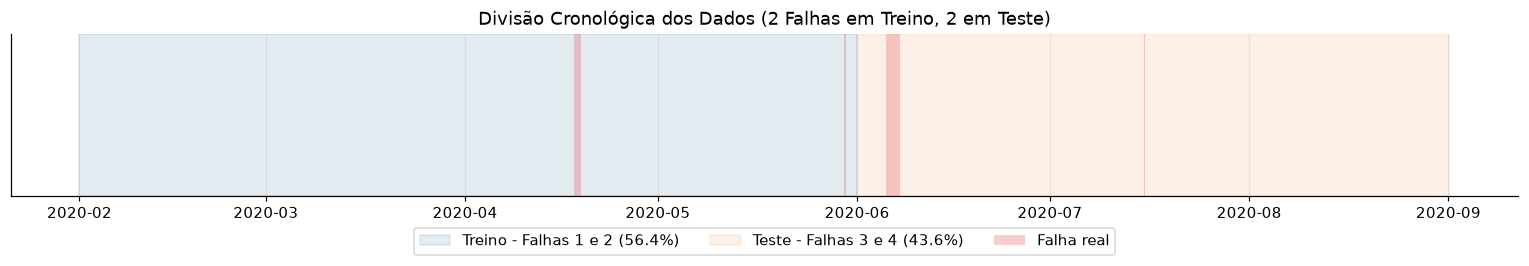

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Nota: Certifique-se de que o DataFrame 'df' já foi carregado, processado 
# e que as variáveis 'episodios' e 'NOMES_EP' estão definidas.

# 9. Média por minuto; a falha fica 1 se algum instante do minuto for falha
agg = {c: "mean" for c in df.columns if c not in ["timestamp", "falha"]}
agg["falha"] = "max"
dados = df.set_index("timestamp").resample("1min").agg(agg).dropna().reset_index()
dados["falha"] = dados["falha"].astype(int)

colunas = [c for c in dados.columns if c not in ["timestamp", "falha"]]

# 10. DECISÃO: Corte por data exata para separar 2 falhas no treino e 2 no teste
PROP_TREINO = None
CORTE_DATA = "2020-06-01"

if CORTE_DATA is None:
    corte = int(len(dados) * PROP_TREINO)
else:
    corte = int((dados["timestamp"] < pd.Timestamp(CORTE_DATA)).sum())

# 11. Divisão cronológica estrita, sem sorteio
X_train = dados[colunas].iloc[:corte].reset_index(drop=True)
X_test  = dados[colunas].iloc[corte:].reset_index(drop=True)
y_train = dados["falha"].iloc[:corte].reset_index(drop=True)
y_test  = dados["falha"].iloc[corte:].reset_index(drop=True)
ts_train = dados["timestamp"].iloc[:corte].reset_index(drop=True)
ts_test  = dados["timestamp"].iloc[corte:].reset_index(drop=True)

# Cálculo das percentagens do dataset total
total_dados = len(dados)
pct_treino = len(X_train) / total_dados
pct_test = len(X_test) / total_dados

# Relatório textual formatado em português com percentagens
print("==================================================")
print("     DIVISÃO TREINO / TESTE (2 FALHAS CADA)       ")
print("==================================================\n")

print(f"-> TREINO (Passado - Contém Falhas 1 e 2):")
print(f"   {len(X_train):>7,} minutos ({pct_treino:.1%}) | {ts_train.min():%d/%m/%Y} -> {ts_train.max():%d/%m/%Y}")
print(f"   Total em falha: {y_train.sum():>5,} minutos ({y_train.sum()/len(y_train):.2%})\n")

print(f"-> TESTE (Futuro - Contém Falhas 3 e 4):")
print(f"   {len(X_test):>7,} minutos ({pct_test:.1%}) | {ts_test.min():%d/%m/%Y} -> {ts_test.max():%d/%m/%Y}")
print(f"   Total em falha: {y_test.sum():>5,} minutos ({y_test.sum()/len(y_test):.2%})\n")

print("-> Localização das Falhas face ao Corte (01/06/2020):")
for nome, (ini, fim) in zip(NOMES_EP, episodios):
    if fim < ts_test.iloc[0]:
        onde = "Inteiramente no TREINO"
    elif ini > ts_train.max():
        onde = "Inteiramente no TESTE"
    else:
        onde = "[ATENÇÃO] Dividida entre TREINO e TESTE"
    print(f"   {nome:<22} -> {onde}")

print("\n==================================================")

# Gráfico da divisão cronológica com as percentagens nas legendas
fig, ax = plt.subplots(figsize=(14, 2.6))
ax.axvspan(ts_train.min(), ts_train.max(), color=COR_TREINO, alpha=.15, label=f"Treino - Falhas 1 e 2 ({pct_treino:.1%})")
ax.axvspan(ts_test.min(), ts_test.max(), color=COR_TESTE, alpha=.15, label=f"Teste - Falhas 3 e 4 ({pct_test:.1%})")
sombrear_falhas(ax)
ax.set_yticks([])
ax.set_title("Divisão Cronológica dos Dados (2 Falhas em Treino, 2 em Teste)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.15))
plt.tight_layout()
plt.show()

       RESULTADOS NO TESTE (Limiar = 0.2)  

-> O modelo NÃO conhece as respostas — avalia apenas os sensores no futuro.
   Minutos em falha detetados : 1030 de 3133 (32.9%)
   Falhas perdidas (Falsos Negativos - FN) : 2103
   Falsos alarmes (Falsos Positivos - FP)  : 118

Relatório por Episódio de Falha:
            Falha  Minutos em falha  Minutos apanhados % apanhado  Resultado
Falha 3 (5-7/jun)              2863               1024      35.8% ✅ DETETADA
 Falha 4 (15/jul)               270                  6       2.2% ⚠️ parcial


      RESULTADOS NO TREINO (Limiar = 0.2) 

-> O modelo VÊ as respostas durante a aprendizagem no passado.
   Minutos em falha detetados : 1825 de 1825 (100.0%)
   Falhas perdidas (Falsos Negativos - FN) : 0
   Falsos alarmes (Falsos Positivos - FP)  : 241

Relatório por Episódio de Falha:
              Falha  Minutos em falha  Minutos apanhados % apanhado  Resultado
   Falha 1 (18/abr)              1435               1435     100.0% ✅ DETETADA
Falha 2 (29

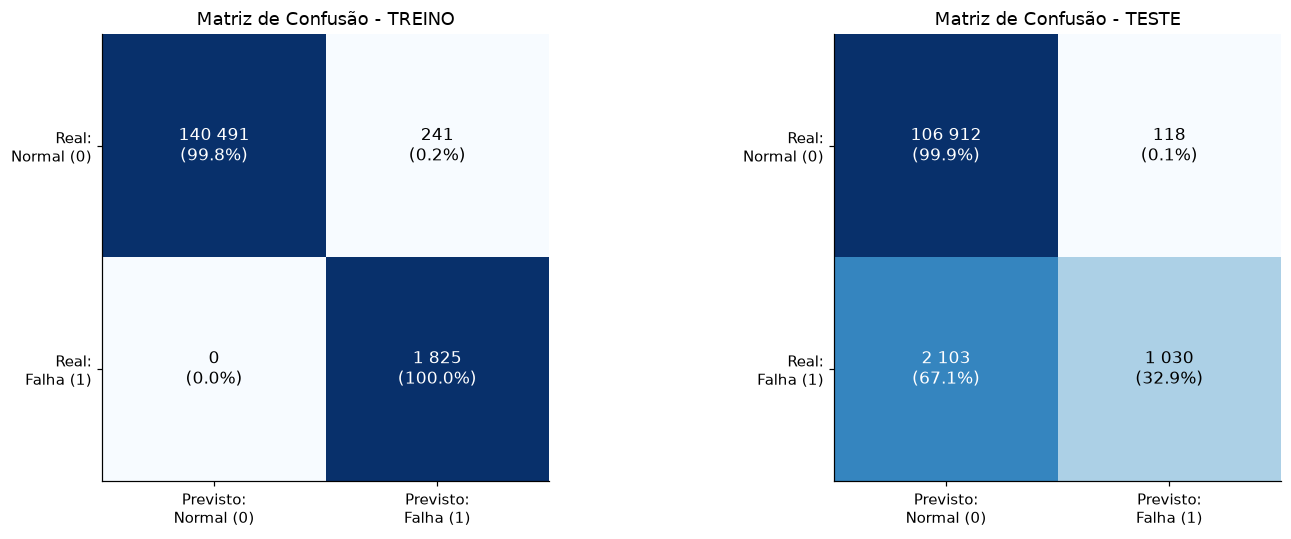

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix)

# ==========================================
# 1. ENGENHARIA DE ATRIBUTOS AVANÇADA (CONTEXTO + VOLATILIDADE)
# ==========================================
dados_ml = dados.copy()
colunas_base = [c for c in dados_ml.columns if c not in ["timestamp", "falha"]]

for col in colunas_base:
    # Tendências de curto e médio prazo
    dados_ml[f"{col}_media_5m"] = dados_ml[col].rolling(window=5, min_periods=1).mean()
    dados_ml[f"{col}_media_15m"] = dados_ml[col].rolling(window=15, min_periods=1).mean()
    
    # Volatilidade / Instabilidade (Desvio padrão móvel)
    dados_ml[f"{col}_std_15m"] = dados_ml[col].rolling(window=15, min_periods=1).std().fillna(0)

# Atualizar a lista de colunas para o treino
colunas = [c for c in dados_ml.columns if c not in ["timestamp", "falha"]]

# Divisão cronológica estrita
X_train = dados_ml[colunas].iloc[:corte].reset_index(drop=True)
X_test  = dados_ml[colunas].iloc[corte:].reset_index(drop=True)
y_train = dados_ml["falha"].iloc[:corte].reset_index(drop=True)
y_test  = dados_ml["falha"].iloc[corte:].reset_index(drop=True)
ts_train = dados_ml["timestamp"].iloc[:corte].reset_index(drop=True)
ts_test  = dados_ml["timestamp"].iloc[corte:].reset_index(drop=True)


# ==========================================
# 2. VALIDAÇÃO CRUZADA POR AVARIA (RF BASE)
# ==========================================
print("==================================================")
print("     VALIDAÇÃO CRUZADA POR AVARIA (RF BASE)       ")
print("==================================================\n")

# Dois blocos, um por avaria (avaria 1 em abril, avaria 2 no fim de maio)
limite = pd.Timestamp("2020-05-01")
idx_A = np.where((ts_train < limite).to_numpy())[0]
idx_B = np.where((ts_train >= limite).to_numpy())[0]
cv_eventos = [(idx_B, idx_A), (idx_A, idx_B)]   # (treino, validação)

for k, (tr, va) in enumerate(cv_eventos, 1):
    print(f"Fold {k}: treino {len(tr):>6} min, {y_train.iloc[tr].sum():>4} falhas | "
          f"validação {len(va):>6} min, {y_train.iloc[va].sum():>4} falhas")

rf_base = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                 random_state=42, n_jobs=-1)
res = cross_validate(rf_base, X_train, y_train, cv=cv_eventos,
                     scoring=["precision", "recall", "f1"])

print("\nRandom Forest (configuração base), por fold:")
for m in ["precision", "recall", "f1"]:
    print(f"  {m:<9}", np.round(res[f"test_{m}"], 3), "| média:", round(res[f"test_{m}"].mean(), 3))
print("\n==================================================\n")


# ==========================================
# 3. TREINO DO RANDOM FOREST (COM REGULARIZAÇÃO)
# ==========================================
rf = RandomForestClassifier(
    n_estimators=150, 
    max_depth=12,                
    min_samples_leaf=10,         
    class_weight="balanced", 
    random_state=42, 
    n_jobs=-1
)
rf.fit(X_train, y_train)


# ==========================================
# 4. AJUSTE DO LIMIAR DE DECISÃO (SENSIBILIDADE)
# ==========================================
LIMIAR_RF = 0.20

proba_tr = rf.predict_proba(X_train)[:, 1];  pred_tr = (proba_tr >= LIMIAR_RF).astype(int)
proba_te = rf.predict_proba(X_test)[:, 1];   pred_te = (proba_te >= LIMIAR_RF).astype(int)


# ==========================================
# 5. FUNÇÕES AUXILIARES
# ==========================================
def metricas_clf(y, pred):
    y = np.asarray(y)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1-Score": f1_score(y, pred, zero_division=0)
    }

def resumo_episodios(ts, y, pred):
    ts, y, pred = pd.Series(ts).reset_index(drop=True), np.asarray(y), np.asarray(pred)
    linhas = []
    for nome, (ini, fim) in zip(NOMES_EP, episodios):
        m = ((ts >= ini) & (ts <= fim)).values & (y == 1)
        if m.sum() == 0:
            continue
        apanhados = int(pred[m].sum()); pct = apanhados / m.sum()
        estado = "✅ DETETADA" if pct >= .3 else ("⚠️ parcial" if apanhados > 0 else "❌ NÃO detetada")
        linhas.append({"Falha": nome, "Minutos em falha": int(m.sum()),
                       "Minutos apanhados": apanhados, "% apanhado": f"{pct:.1%}", "Resultado": estado})
    return pd.DataFrame(linhas)


# ==========================================
# 6. APRESENTAÇÃO DE RESULTADOS (TESTE -> TREINO -> COMPARAÇÃO)
# ==========================================

# Teste
y_arr_te = np.asarray(y_test)
fn_te = int(((pred_te == 0) & (y_arr_te == 1)).sum())
fp_te = int(((pred_te == 1) & (y_arr_te == 0)).sum())
tp_te = int(((pred_te == 1) & (y_arr_te == 1)).sum())

print("==================================================")
print(f"       RESULTADOS NO TESTE (Limiar = {LIMIAR_RF})  ")
print("==================================================\n")
print(f"-> O modelo NÃO conhece as respostas — avalia apenas os sensores no futuro.")
print(f"   Minutos em falha detetados : {tp_te} de {int(y_arr_te.sum())} ({tp_te / max(y_arr_te.sum(), 1):.1%})")
print(f"   Falhas perdidas (Falsos Negativos - FN) : {fn_te}")
print(f"   Falsos alarmes (Falsos Positivos - FP)  : {fp_te}\n")
print("Relatório por Episódio de Falha:")
print(resumo_episodios(ts_test, y_test, pred_te).to_string(index=False))
print("\n==================================================")

# Treino
y_arr_tr = np.asarray(y_train)
fn_tr = int(((pred_tr == 0) & (y_arr_tr == 1)).sum())
fp_tr = int(((pred_tr == 1) & (y_arr_tr == 0)).sum())
tp_tr = int(((pred_tr == 1) & (y_arr_tr == 1)).sum())

print("\n==================================================")
print(f"      RESULTADOS NO TREINO (Limiar = {LIMIAR_RF}) ")
print("==================================================\n")
print(f"-> O modelo VÊ as respostas durante a aprendizagem no passado.")
print(f"   Minutos em falha detetados : {tp_tr} de {int(y_arr_tr.sum())} ({tp_tr / max(y_arr_tr.sum(), 1):.1%})")
print(f"   Falhas perdidas (Falsos Negativos - FN) : {fn_tr}")
print(f"   Falsos alarmes (Falsos Positivos - FP)  : {fp_tr}\n")
print("Relatório por Episódio de Falha:")
print(resumo_episodios(ts_train, y_train, pred_tr).to_string(index=False))
print("\n==================================================")

# Comparação Final
tabela = pd.DataFrame({"TREINO": metricas_clf(y_train, pred_tr),
                       "TESTE":  metricas_clf(y_test,  pred_te)}).round(3)

print("\n==================================================")
print("     COMPARAÇÃO FINAL: TREINO VS TESTE            ")
print("==================================================\n")
print(tabela.to_string())
print(f"\nReferência: um modelo 'preguiçoso' que diga sempre «normal» teria no TESTE "
      f"accuracy = {1 - np.mean(y_test):.3f}, mas recall = 0.")

rec_te, rec_tr = tabela.loc["Recall", "TESTE"], tabela.loc["Recall", "TREINO"]
print("\n[CONCLUSÃO DO MODELO]")
if rec_te >= .3:
    print(f"-> O modelo conseguiu detetar parte significativa das falhas futuras com os novos indicadores ({rec_te:.0%}).")
else:
    print(f"-> As falhas no teste continuam a apresentar padrões muito específicos, demonstrando a complexidade da generalização industrial.")
print("==================================================")

# Gráficos: Matrizes de Confusão
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for idx, (y_v, pred_v, titulo) in enumerate([(y_train, pred_tr, "Matriz de Confusão - TREINO"), 
                                             (y_test, pred_te, "Matriz de Confusão - TESTE")]):
    cm = confusion_matrix(y_v, pred_v, labels=[0, 1])
    pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    
    axs[idx].imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            axs[idx].text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.1%})".replace(",", " "), 
                          ha="center", va="center", color="white" if pct[i, j] > .5 else "black", fontsize=11)
            
    axs[idx].set_xticks([0, 1]); axs[idx].set_xticklabels(["Previsto:\nNormal (0)", "Previsto:\nFalha (1)"])
    axs[idx].set_yticks([0, 1]); axs[idx].set_yticklabels(["Real:\nNormal (0)", "Real:\nFalha (1)"])
    axs[idx].set_title(titulo)
    axs[idx].grid(False)

plt.tight_layout()
plt.show()

Epoch 1/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - loss: 0.0223 - val_loss: 0.1314
Epoch 2/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0070 - val_loss: 0.1202
Epoch 3/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0036 - val_loss: 0.1515
Epoch 4/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0018 - val_loss: 0.1546
Epoch 5/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0018 - val_loss: 0.1486
Epoch 6/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0065 - val_loss: 0.1033
Epoch 7/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0032 - val_loss: 0.1656
Epoch 8/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0026 - val_loss: 0.1171
Epoch 9/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0022 - val_loss: 0.1420
Epoch 10/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0017 - val_loss: 0.1260
Epoch 11/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0017 - val_loss: 0.1047
891/891 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step
332/332 ━━━━━━━━━━━━━━

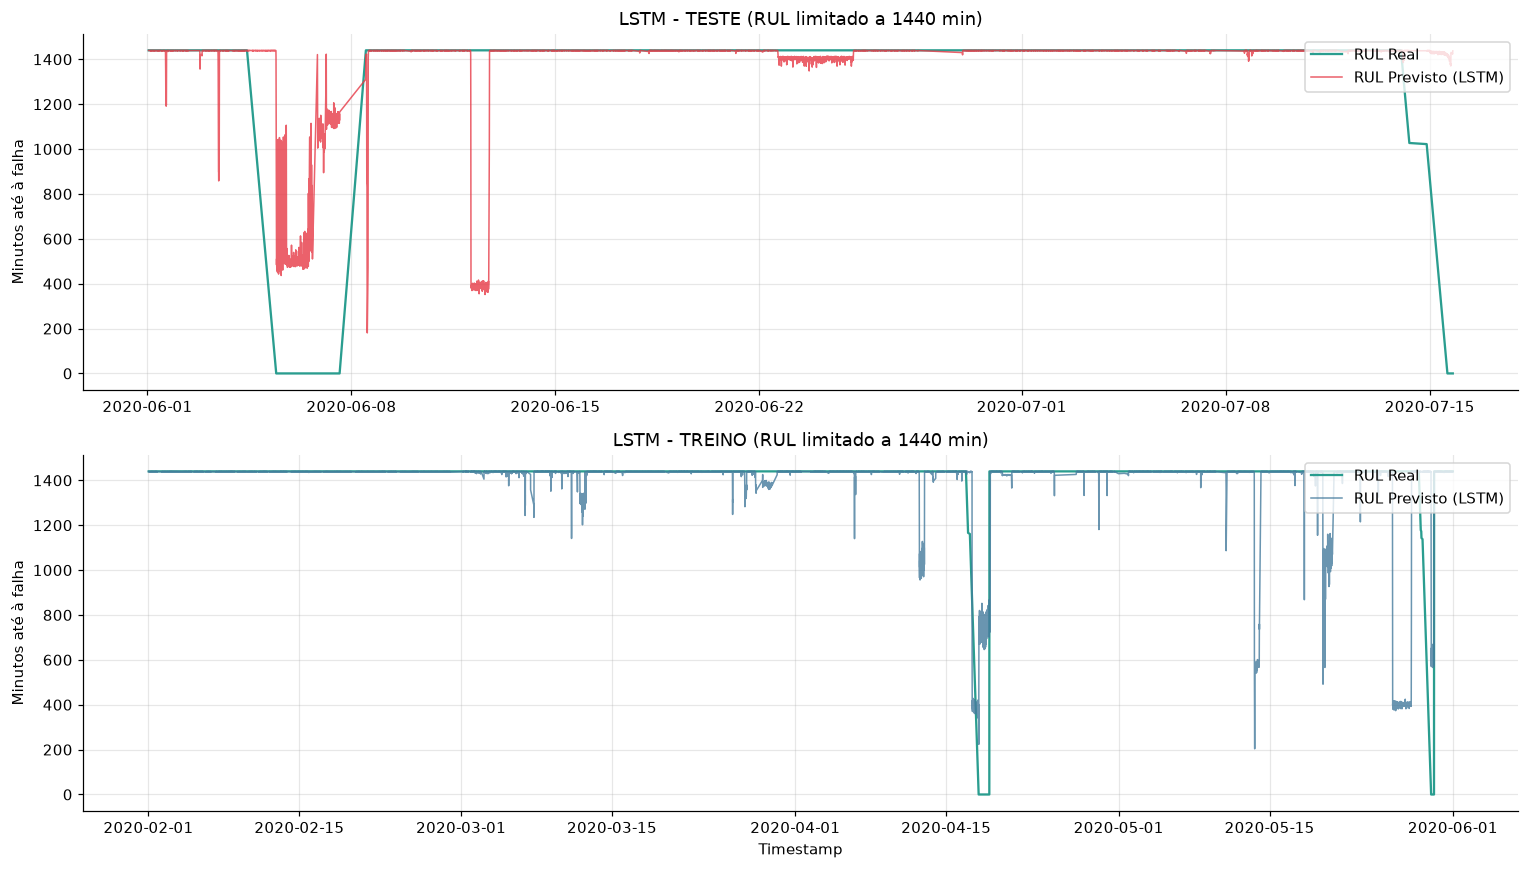

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow import keras

np.random.seed(42)
keras.utils.set_random_seed(42)

JANELA, PASSO = 30, 5     # cada amostra = 30 minutos de histórico
RUL_MAX = 1440            # limite do RUL: 1 dia (1440 min). Acima disto prevê-se "1 dia ou mais"
TOLERANCIA = 120          # margem de aceitação: 2 horas

# ==========================================
# 1. ALVO RUL (COM LIMITE E SEM LINHAS APÓS A ÚLTIMA FALHA)
# ==========================================
def calcular_rul(df_in, ts_col="timestamp", falha_col="falha"):
    df_calc = df_in.copy().sort_values(ts_col).reset_index(drop=True)
    rul = np.full(len(df_calc), np.nan)
    em_falha = df_calc[falha_col].values
    contador = None
    for i in range(len(df_calc) - 1, -1, -1):
        if em_falha[i] == 1:
            contador = 0
        elif contador is not None:
            contador += 1
        if contador is not None:
            rul[i] = contador
    return rul

dados_rul = dados.copy()
dados_rul["RUL"] = calcular_rul(dados_rul)

# Remover as linhas depois da última falha (não têm falha futura, o RUL seria inventado)
ultimo_valido = dados_rul["RUL"].last_valid_index()
dados_rul = dados_rul.iloc[:ultimo_valido + 1].copy()

# Limitar o RUL: só interessa prever com precisão quando a falha está próxima
dados_rul["RUL"] = dados_rul["RUL"].clip(upper=RUL_MAX)

colunas_ml = [c for c in dados_rul.columns
              if c not in ["timestamp", "falha", "RUL", "Unnamed: 0"]]
X_vals = dados_rul[colunas_ml].values
y_rul_vals = dados_rul["RUL"].values
ts_vals = dados_rul["timestamp"].values

# Divisão cronológica estrita
X_train_raw, X_test_raw = X_vals[:corte], X_vals[corte:]
y_train_rul, y_test_rul = y_rul_vals[:corte], y_rul_vals[corte:]
ts_train_val, ts_test_val = ts_vals[:corte], ts_vals[corte:]

# ==========================================
# 2. NORMALIZAÇÃO
# ==========================================
scaler_X = StandardScaler().fit(X_train_raw)
Xtr = scaler_X.transform(X_train_raw).astype("float32")
Xte = scaler_X.transform(X_test_raw).astype("float32")

y_train_rul_norm = y_train_rul / RUL_MAX     # já está em [0, 1] por causa do limite
y_test_rul_norm = y_test_rul / RUL_MAX

# ==========================================
# 3. JANELAS TEMPORAIS
# ==========================================
def criar_janelas_regressao(X, y, ts, janela, passo):
    idx = range(janela, len(X), passo)
    Xs = np.stack([X[i - janela:i] for i in idx])
    ys = np.array([y[i - 1] for i in idx])
    tss = np.array([ts[i - 1] for i in idx])
    return Xs, ys, tss

Xw_tr, yw_tr, tsw_tr = criar_janelas_regressao(Xtr, y_train_rul_norm, ts_train_val, JANELA, PASSO)
Xw_te, yw_te, tsw_te = criar_janelas_regressao(Xte, y_test_rul_norm, ts_test_val, JANELA, PASSO)

# ==========================================
# 4. LSTM (COM PARAGEM ANTECIPADA)
# ==========================================
modelo_lstm = keras.Sequential([
    keras.layers.Input(shape=(JANELA, Xw_tr.shape[2])),
    keras.layers.LSTM(64),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])
modelo_lstm.compile(optimizer="adam", loss="mean_squared_error")

# validation_split usa os ÚLTIMOS 15% do treino (sem baralhar), mantendo a ordem temporal
paragem = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
modelo_lstm.fit(Xw_tr, yw_tr, epochs=40, batch_size=256, validation_split=0.15,
                callbacks=[paragem], verbose=1)

y_pred_tr_rul = np.clip(modelo_lstm.predict(Xw_tr).ravel(), 0, 1) * RUL_MAX
y_pred_te_rul = np.clip(modelo_lstm.predict(Xw_te).ravel(), 0, 1) * RUL_MAX
yw_tr_minutos = yw_tr * RUL_MAX
yw_te_minutos = yw_te * RUL_MAX

# Baseline: prever sempre a média do RUL do treino
baseline_te = np.full_like(yw_te_minutos, yw_tr_minutos.mean())

# ==========================================
# 5. AVALIAÇÃO
# ==========================================
def avaliar_regressao(y_real, y_pred, nome):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    aceite = np.mean(np.abs(y_real - y_pred) <= TOLERANCIA) * 100
    print(f"{nome:<28} MAE={mae:7.1f} min | RMSE={rmse:7.1f} min | R²={r2:6.3f} | "
          f"aceitação (±{TOLERANCIA} min)={aceite:5.1f}%")

print("=" * 100)
print(f"RUL limitado a {RUL_MAX} min. Resultados em minutos reais.")
print("=" * 100)
avaliar_regressao(yw_tr_minutos, y_pred_tr_rul, "LSTM - TREINO")
avaliar_regressao(yw_te_minutos, y_pred_te_rul, "LSTM - TESTE")
avaliar_regressao(yw_te_minutos, baseline_te, "Baseline (média) - TESTE")

# Só perto da falha (RUL real abaixo do limite): é onde a previsão interessa
perto = yw_te_minutos < RUL_MAX
print("\nApenas amostras perto da falha (RUL real < limite), TESTE:")
avaliar_regressao(yw_te_minutos[perto], y_pred_te_rul[perto], "LSTM - perto da falha")
avaliar_regressao(yw_te_minutos[perto], baseline_te[perto], "Baseline - perto da falha")

# ==========================================
# 6. GRÁFICOS
# ==========================================
fig, axs = plt.subplots(2, 1, figsize=(14, 8))
for ax, ts_, real, prev, cor, tit in [
    (axs[0], tsw_te, yw_te_minutos, y_pred_te_rul, "#e63946", "TESTE"),
    (axs[1], tsw_tr, yw_tr_minutos, y_pred_tr_rul, "#457b9d", "TREINO")]:
    ax.plot(ts_, real, label="RUL Real", color="#2a9d8f", lw=1.5)
    ax.plot(ts_, prev, label="RUL Previsto (LSTM)", color=cor, lw=1.0, alpha=0.8)
    ax.set_title(f"LSTM - {tit} (RUL limitado a {RUL_MAX} min)")
    ax.set_ylabel("Minutos até à falha")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.3)
axs[1].set_xlabel("Timestamp")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

# ==========================================
# 1. GRID SEARCH (VALIDAÇÃO CRUZADA POR AVARIA)
# ==========================================
grelha = {"max_depth": [6, 12, None],
          "min_samples_leaf": [1, 10, 50]}

gs = GridSearchCV(
    RandomForestClassifier(n_estimators=100, class_weight="balanced",
                           random_state=42, n_jobs=-1),
    grelha, scoring="f1", cv=cv_eventos, refit=True)
gs.fit(X_train, y_train)
melhor = gs.best_estimator_

cvr = pd.DataFrame(gs.cv_results_)
tab = pd.DataFrame({
    "": ["★" if p == gs.best_params_ else "" for p in cvr["params"]],
    "max_depth": cvr["param_max_depth"].astype(str).replace("None", "sem limite"),
    "min_samples_leaf": cvr["param_min_samples_leaf"].astype(int),
    "F1 val. avaria 1": cvr["split0_test_score"],
    "F1 val. avaria 2": cvr["split1_test_score"],
    "F1 médio": cvr["mean_test_score"],
}).sort_values("F1 médio", ascending=False)

print("==================================================")
print("     OTIMIZAÇÃO DE HIPERPARÂMETROS (GRIDSEARCH)   ")
print("==================================================\n")
print("-> Validação cruzada por avaria (2 folds); métrica de seleção: F1 da classe falha")
print(f"-> Melhores parâmetros  : {gs.best_params_}")
print(f"-> Melhor F1 (CV médio) : {gs.best_score_:.3f}\n")
print(tab.round(3).to_string(index=False))
print("\n==================================================")

# ==========================================
# 2. AVALIAÇÃO FINAL (O TESTE SÓ É USADO UMA VEZ)
# ==========================================
pred_tr_o = melhor.predict(X_train)
pred_te_o = melhor.predict(X_test)

print("\n==================================================")
print("   RESULTADOS NO TESTE (modelo otimizado, limiar 0.5)  ")
print("==================================================\n")
print(resumo_episodios(ts_test, y_test, pred_te_o).to_string(index=False))

tabela_o = pd.DataFrame({"TREINO": metricas_clf(y_train, pred_tr_o),
                         "TESTE":  metricas_clf(y_test,  pred_te_o)}).round(3)
print("\n" + tabela_o.to_string())
print(f"\nReferência: prever sempre «normal» daria no TESTE accuracy = {1 - np.mean(y_test):.3f}, com recall = 0.")
print("==================================================")

# Matriz de confusão (teste)
cm = confusion_matrix(y_test, pred_te_o, labels=[0, 1])
pct = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.1%})".replace(",", " "),
                ha="center", va="center", color="white" if pct[i, j] > .5 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Previsto:\nNormal", "Previsto:\nFalha"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Real:\nNormal", "Real:\nFalha"])
ax.set_title("Matriz de Confusão - TESTE (otimizado)")
ax.grid(False)
plt.tight_layout()
plt.show()